In [1]:
# AICS-201: AI Ethics, Governance and Legal Frameworks
# Practical Assessment: Algorithmic Fairness and Explainability
# Organisation: SecureFinance Africa
# Data classification: Synthetic / Fictional

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    false_positive_rate,
    false_negative_rate,
    true_positive_rate
)

# Set random seed for reproducibility
np.random.seed(42)

# Configure visualisation
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("AICS-201 Fairness Assessment Environment")
print("-----------------------------------------")
print("All required libraries imported successfully.")
print("Random seed: 42")
print("Data classification: Synthetic")

AICS-201 Fairness Assessment Environment
-----------------------------------------
All required libraries imported successfully.
Random seed: 42
Data classification: Synthetic


In [2]:

# STEP 1: GENERATE SYNTHETIC FINANCIAL CUSTOMER DATA

import pandas as pd
import numpy as np

# Reproducible random generator
rng = np.random.default_rng(42)

# Number of fictional customers
n = 500

# Generate customer attributes
df = pd.DataFrame({
    "customer_id": [f"SFA{i:04d}" for i in range(1, n + 1)],
    "gender": rng.choice(["Female", "Male"], n),
    "age": rng.integers(21, 66, n),
    "monthly_income": rng.integers(80000, 1000001, n),
    "credit_history_years": rng.integers(0, 21, n),
    "debt_to_income": rng.uniform(0.05, 0.75, n).round(3),
    "missed_payments": rng.integers(0, 7, n),
    "account_age_months": rng.integers(1, 121, n)
})

# Generate an unbiased financial assessment score
financial_score = (
    0.30 * (df["monthly_income"] / 1000000)
    + 0.20 * (df["credit_history_years"] / 20)
    + 0.25 * (1 - df["debt_to_income"])
    + 0.15 * (1 - df["missed_payments"] / 6)
    + 0.10 * (df["account_age_months"] / 120)
)

# Simulated actual eligibility based on financial characteristics
financial_score += rng.normal(0, 0.04, n)

df["actual_eligible"] = (financial_score >= 0.55).astype(int)

# Introduce a controlled gender-related bias into simulated AI predictions
prediction_score = (
    financial_score
    - np.where(df["gender"] == "Female", 0.08, 0.0)
    + rng.normal(0, 0.025, n)
)

df["ai_predicted_eligible"] = (
    prediction_score >= 0.55
).astype(int)

# Save synthetic dataset
df.to_csv("synthetic_dataset.csv", index=False)

# Display initial results
print("SYNTHETIC DATASET GENERATED SUCCESSFULLY")
print("----------------------------------------")
print("Total customer records:", len(df))
print("Dataset columns:", len(df.columns))
print("\nFirst five customer records:")
display(df.head())

print("\nGender distribution:")
print(df["gender"].value_counts())

print("\nDataset saved as synthetic_dataset.csv")


SYNTHETIC DATASET GENERATED SUCCESSFULLY
----------------------------------------
Total customer records: 500
Dataset columns: 10

First five customer records:


,customer_id,gender,age,monthly_income,credit_history_years,debt_to_income,missed_payments,account_age_months,actual_eligible,ai_predicted_eligible
0,SFA0001,Female,26,823637,11,0.093,5,8,1,0
1,SFA0002,Male,50,757769,5,0.371,4,77,1,1
2,SFA0003,Male,64,593652,4,0.140,6,38,0,0
3,SFA0004,Female,60,895491,6,0.157,6,25,0,0
4,SFA0005,Female,33,198006,12,0.493,4,3,0,0



Gender distribution:
gender
Female    256
Male      244
Name: count, dtype: int64

Dataset saved as synthetic_dataset.csv


In [3]:
# STEP 2: DATASET VALIDATION

print("DATASET VALIDATION REPORT")
print("=" * 40)

# Dataset dimensions
print("Dataset shape:", df.shape)

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Gender distribution
print("\nGender distribution:")
print(df["gender"].value_counts())

# Actual eligibility distribution
print("\nActual eligibility:")
print(df["actual_eligible"].value_counts())

# AI prediction distribution
print("\nAI predicted eligibility:")
print(df["ai_predicted_eligible"].value_counts())

# Compare eligibility by gender
print("\nActual eligibility by gender:")
print(pd.crosstab(
    df["gender"],
    df["actual_eligible"],
    normalize="index"
).round(3))

print("\nAI predicted eligibility by gender:")
print(pd.crosstab(
    df["gender"],
    df["ai_predicted_eligible"],
    normalize="index"
).round(3))

DATASET VALIDATION REPORT
Dataset shape: (500, 10)

Missing values:
customer_id              0
gender                   0
age                      0
monthly_income           0
credit_history_years     0
debt_to_income           0
missed_payments          0
account_age_months       0
actual_eligible          0
ai_predicted_eligible    0
dtype: int64

Duplicate records: 0

Gender distribution:
gender
Female    256
Male      244
Name: count, dtype: int64

Actual eligibility:
actual_eligible
0    270
1    230
Name: count, dtype: int64

AI predicted eligibility:
ai_predicted_eligible
0    321
1    179
Name: count, dtype: int64

Actual eligibility by gender:
actual_eligible      0      1
gender                       
Female           0.527  0.473
Male             0.553  0.447

AI predicted eligibility by gender:
ai_predicted_eligible      0      1
gender                             
Female                 0.730  0.270
Male                   0.549  0.451


In [4]:

# STEP 3: FAIRNESS METRICS USING FAIRLEARN

from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    false_positive_rate,
    false_negative_rate,
    true_positive_rate
)

# Reference outcomes and simulated AI predictions
y_true = df["actual_eligible"]
y_pred = df["ai_predicted_eligible"]

# Sensitive feature
sensitive_feature = df["gender"]

# Calculate metrics for each gender group
fairness_metrics = MetricFrame(
    metrics={
        "Selection Rate": selection_rate,
        "False Positive Rate": false_positive_rate,
        "False Negative Rate": false_negative_rate,
        "True Positive Rate": true_positive_rate
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_feature
)

# Display group-level results
print("FAIRNESS METRICS BY GENDER")
print("=" * 55)
display(fairness_metrics.by_group.round(4))

# Calculate maximum difference between groups
print("\nBETWEEN-GROUP DIFFERENCES")
print("=" * 55)
display(fairness_metrics.difference(method="between_groups").round(4))

# Calculate between-group ratios
print("\nBETWEEN-GROUP RATIOS")
print("=" * 55)
display(fairness_metrics.ratio(method="between_groups").round(4))


FAIRNESS METRICS BY GENDER


,Selection Rate,False Positive Rate,False Negative Rate,True Positive Rate
gender,,,,
Female,0.2695,0.0000,0.4298,0.5702
Male,0.4508,0.0593,0.0642,0.9358



BETWEEN-GROUP DIFFERENCES


Selection Rate         0.1813
False Positive Rate    0.0593
False Negative Rate    0.3655
True Positive Rate     0.3655
dtype: float64


BETWEEN-GROUP RATIOS


Selection Rate         0.5979
False Positive Rate    0.0000
False Negative Rate    0.1494
True Positive Rate     0.6094
dtype: float64

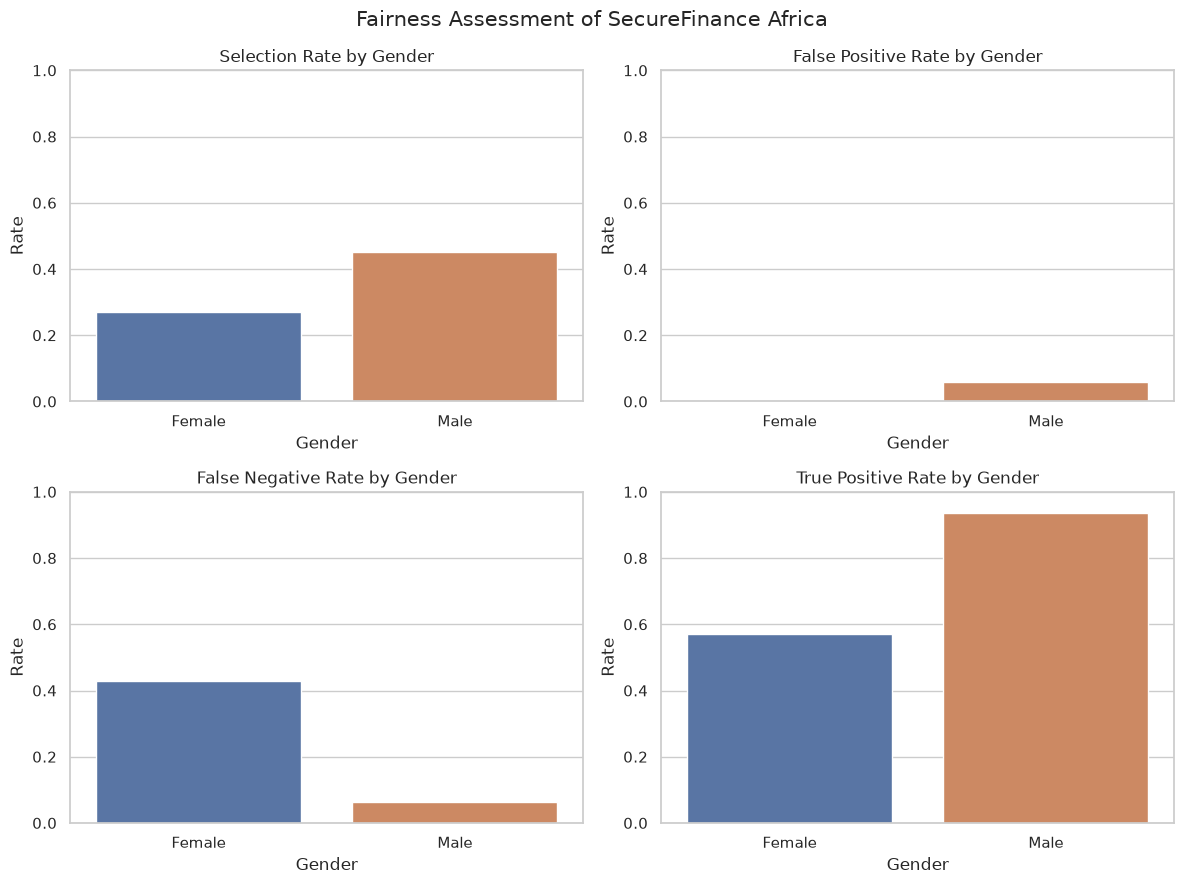

Fairness visualisation saved successfully.


In [5]:

# STEP 4: FAIRNESS METRICS VISUALISATION

metrics_df = fairness_metrics.by_group.reset_index()

metrics_to_plot = [
    "Selection Rate",
    "False Positive Rate",
    "False Negative Rate",
    "True Positive Rate"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, metric in zip(axes.flatten(), metrics_to_plot):
    sns.barplot(
        data=metrics_df,
        x="gender",
        y=metric,
        hue="gender",
        legend=False,
        ax=ax
    )
    ax.set_title(metric + " by Gender")
    ax.set_xlabel("Gender")
    ax.set_ylabel("Rate")
    ax.set_ylim(0, 1)

plt.suptitle(
    "Fairness Assessment of SecureFinance Africa",
    fontsize=15
)

plt.tight_layout()

# Save visualisation
plt.savefig(
    "visualisations/fairness_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Fairness visualisation saved successfully.")


In [6]:

# STEP 5: INDIVIDUAL DECISION REVIEW

# Reconstruct the decision scores for explanation
df["financial_score"] = (
    0.30 * (df["monthly_income"] / 1000000)
    + 0.20 * (df["credit_history_years"] / 20)
    + 0.25 * (1 - df["debt_to_income"])
    + 0.15 * (1 - df["missed_payments"] / 6)
    + 0.10 * (df["account_age_months"] / 120)
    + 0  # Score components before random reference noise
)

# Reconstruct the prediction score used in the simulation
df["prediction_score"] = (
    df["financial_score"]
    - np.where(df["gender"] == "Female", 0.08, 0.0)
)

# Select five fictional customers
review = df[
    [
        "customer_id",
        "gender",
        "monthly_income",
        "credit_history_years",
        "debt_to_income",
        "missed_payments",
        "actual_eligible",
        "ai_predicted_eligible",
        "prediction_score"
    ]
].head(5)

print("INDIVIDUAL CUSTOMER DECISION REVIEW")
display(review.round(3))


INDIVIDUAL CUSTOMER DECISION REVIEW


,customer_id,gender,monthly_income,credit_history_years,debt_to_income,missed_payments,actual_eligible,ai_predicted_eligible,prediction_score
0,SFA0001,Female,823637,11,0.093,5,1,0,0.536
1,SFA0002,Male,757769,5,0.371,4,1,1,0.549
2,SFA0003,Male,593652,4,0.140,6,0,0,0.465
3,SFA0004,Female,895491,6,0.157,6,0,0,0.480
4,SFA0005,Female,198006,12,0.493,4,0,0,0.279


In [7]:

# STEP 6: REPRODUCIBLE DECISION SCORE VALIDATION

rng = np.random.default_rng(42)
n = 500

# Reproduce the original customer attributes
df = pd.DataFrame({
    "customer_id": [f"SFA{i:04d}" for i in range(1, n + 1)],
    "gender": rng.choice(["Female", "Male"], n),
    "age": rng.integers(21, 66, n),
    "monthly_income": rng.integers(80000, 1000001, n),
    "credit_history_years": rng.integers(0, 21, n),
    "debt_to_income": rng.uniform(0.05, 0.75, n).round(3),
    "missed_payments": rng.integers(0, 7, n),
    "account_age_months": rng.integers(1, 121, n)
})

# Reconstruct reference financial score
financial_score = (
    0.30 * (df["monthly_income"] / 1000000)
    + 0.20 * (df["credit_history_years"] / 20)
    + 0.25 * (1 - df["debt_to_income"])
    + 0.15 * (1 - df["missed_payments"] / 6)
    + 0.10 * (df["account_age_months"] / 120)
)

financial_score += rng.normal(0, 0.04, n)

# Store reference score
df["financial_score"] = financial_score

df["actual_eligible"] = (
    financial_score >= 0.55
).astype(int)

# Reconstruct simulated AI prediction score
gender_penalty = np.where(
    df["gender"] == "Female", 0.08, 0.0
)

df["gender_penalty"] = gender_penalty

prediction_score = (
    financial_score
    - gender_penalty
    + rng.normal(0, 0.025, n)
)

df["prediction_score"] = prediction_score

df["ai_predicted_eligible"] = (
    prediction_score >= 0.55
).astype(int)

# Save corrected reproducible dataset
df.to_csv("synthetic_dataset.csv", index=False)

print("DECISION SCORE RECONSTRUCTION")
print("=" * 45)
print("Customer records:", len(df))
print("Reference score and prediction score preserved.")
print("Gender penalty documented.")
print("Dataset updated successfully.")


DECISION SCORE RECONSTRUCTION
Customer records: 500
Reference score and prediction score preserved.
Gender penalty documented.
Dataset updated successfully.


In [8]:
# INDIVIDUAL CUSTOMER DECISION REVIEW

review_columns = [
    "customer_id",
    "gender",
    "financial_score",
    "gender_penalty",
    "prediction_score",
    "actual_eligible",
    "ai_predicted_eligible"
]

display(df[review_columns].head(10).round(4))

,customer_id,gender,financial_score,gender_penalty,prediction_score,actual_eligible,ai_predicted_eligible
0,SFA0001,Female,0.5745,0.08,0.4968,1,0
1,SFA0002,Male,0.5851,0.00,0.6100,1,1
2,SFA0003,Male,0.4167,0.00,0.4015,0,0
3,SFA0004,Female,0.5488,0.08,0.4227,0,0
4,SFA0005,Female,0.3352,0.08,0.2073,0,0
5,SFA0006,Male,0.6927,0.00,0.6612,1,1
6,SFA0007,Female,0.6335,0.08,0.5206,1,0
7,SFA0008,Male,0.6156,0.00,0.6117,1,1
8,SFA0009,Female,0.5633,0.08,0.4536,1,0
9,SFA0010,Female,0.4950,0.08,0.3974,0,0


In [9]:

# STEP 7: COUNTERFACTUAL DECISION ANALYSIS

# Reconstruct the random noise used in original predictions
rng = np.random.default_rng(42)

# Advance generator through the original dataset creation
rng.choice(["Female", "Male"], n)
rng.integers(21, 66, n)
rng.integers(80000, 1000001, n)
rng.integers(0, 21, n)
rng.uniform(0.05, 0.75, n)
rng.integers(0, 7, n)
rng.integers(1, 121, n)

# Advance through reference score noise
rng.normal(0, 0.04, n)

# Reproduce prediction noise
prediction_noise = rng.normal(0, 0.025, n)

# Original prediction score
original_score = (
    df["financial_score"]
    - df["gender_penalty"]
    + prediction_noise
)

# Counterfactual score without gender penalty
counterfactual_score = (
    df["financial_score"]
    + prediction_noise
)

# Compare original and counterfactual decisions
df["original_decision"] = (
    original_score >= 0.55
).astype(int)

df["counterfactual_decision"] = (
    counterfactual_score >= 0.55
).astype(int)

df["decision_changed"] = (
    df["original_decision"]
    != df["counterfactual_decision"]
)

# Display affected customers
print("COUNTERFACTUAL FAIRNESS REVIEW")
print("=" * 50)

print(
    "Decisions changed after removing gender penalty:",
    df["decision_changed"].sum()
)

print("\nDecision changes by gender:")

display(
    df.groupby("gender")["decision_changed"]
    .agg(["sum", "mean"])
    .rename(columns={
        "sum": "Changed Decisions",
        "mean": "Proportion Changed"
    }).round(4)
)

print("\nFirst five affected customers:")

display(
    df.loc[
        df["decision_changed"],
        [
            "customer_id",
            "gender",
            "financial_score",
            "original_decision",
            "counterfactual_decision"
        ]
    ].head(5)
)


COUNTERFACTUAL FAIRNESS REVIEW
Decisions changed after removing gender penalty: 52

Decision changes by gender:


,Changed Decisions,Proportion Changed
gender,,
Female,52,0.2031
Male,0,0.0000



First five affected customers:


,customer_id,gender,financial_score,original_decision,counterfactual_decision
0,SFA0001,Female,0.574527,0,1
6,SFA0007,Female,0.633459,0,1
22,SFA0023,Female,0.559736,0,1
64,SFA0065,Female,0.670747,0,1
69,SFA0070,Female,0.516122,0,1


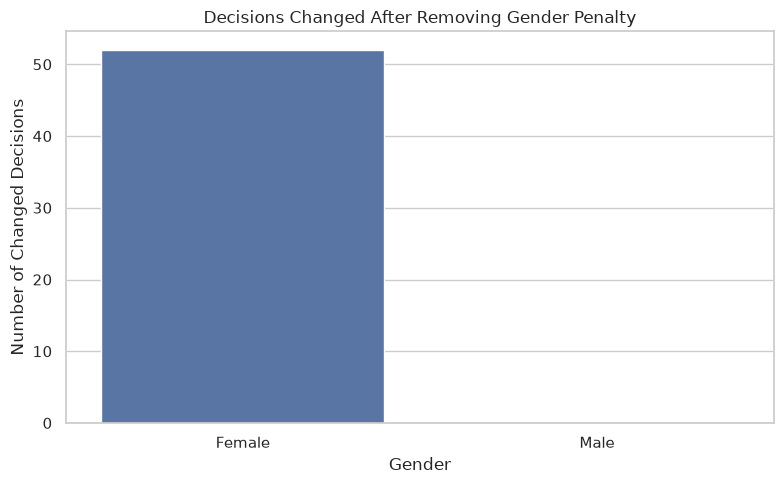

Counterfactual visualisation saved successfully.


In [10]:

# STEP 8: COUNTERFACTUAL ANALYSIS VISUALISATION

counterfactual_summary = (
    df.groupby("gender")["decision_changed"]
    .sum()
    .reset_index()
)

counterfactual_summary.columns = [
    "Gender",
    "Changed Decisions"
]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=counterfactual_summary,
    x="Gender",
    y="Changed Decisions",
    hue="Gender",
    legend=False
)

plt.title("Decisions Changed After Removing Gender Penalty")
plt.xlabel("Gender")
plt.ylabel("Number of Changed Decisions")

plt.tight_layout()

plt.savefig(
    "visualisations/counterfactual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Counterfactual visualisation saved successfully.")


In [11]:

# STEP 9: EXPORT FAIRNESS ASSESSMENT EVIDENCE

import os

# Create evidence output directory
os.makedirs("analysis_results", exist_ok=True)

# 1. Export fairness metrics by gender
fairness_metrics.by_group.to_csv(
    "analysis_results/fairness_metrics_by_gender.csv"
)

# 2. Export between-group differences
fairness_metrics.difference(
    method="between_groups"
).to_csv(
    "analysis_results/fairness_group_differences.csv"
)

# 3. Export between-group ratios
fairness_metrics.ratio(
    method="between_groups"
).to_csv(
    "analysis_results/fairness_group_ratios.csv"
)

# 4. Export counterfactual results
df[[
    "customer_id",
    "gender",
    "financial_score",
    "gender_penalty",
    "original_decision",
    "counterfactual_decision",
    "decision_changed"
]].to_csv(
    "analysis_results/counterfactual_results.csv",
    index=False
)

# 5. Export individual decision review
df[[
    "customer_id",
    "gender",
    "financial_score",
    "prediction_score",
    "actual_eligible",
    "ai_predicted_eligible"
]].to_csv(
    "analysis_results/individual_decision_review.csv",
    index=False
)

print("ANALYTICAL EVIDENCE EXPORT")
print("=" * 40)
print("Fairness metrics exported.")
print("Group differences exported.")
print("Group ratios exported.")
print("Counterfactual results exported.")
print("Individual decision review exported.")
print("\nAll evidence files saved successfully.")


ANALYTICAL EVIDENCE EXPORT
Fairness metrics exported.
Group differences exported.
Group ratios exported.
Counterfactual results exported.
Individual decision review exported.

All evidence files saved successfully.


In [12]:

# FINAL CONSISTENCY CHECK AND FAIRNESS RECALCULATION

from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    false_positive_rate,
    false_negative_rate,
    true_positive_rate
)

y_true = df["actual_eligible"]
y_pred = df["ai_predicted_eligible"]

fairness_metrics = MetricFrame(
    metrics={
        "Selection Rate": selection_rate,
        "False Positive Rate": false_positive_rate,
        "False Negative Rate": false_negative_rate,
        "True Positive Rate": true_positive_rate
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=df["gender"]
)

print("FINAL DATASET VALIDATION")
print("=" * 40)
print("Records:", len(df))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

print("\nFINAL FAIRNESS METRICS")
display(fairness_metrics.by_group.round(4))

print("\nFINAL GROUP DIFFERENCES")
display(
    fairness_metrics.difference(
        method="between_groups"
    ).round(4)
)

print("\nFINAL GROUP RATIOS")
display(
    fairness_metrics.ratio(
        method="between_groups"
    ).round(4)
)


FINAL DATASET VALIDATION
Records: 500
Missing values: 0
Duplicate records: 0

FINAL FAIRNESS METRICS


,Selection Rate,False Positive Rate,False Negative Rate,True Positive Rate
gender,,,,
Female,0.2695,0.0000,0.4298,0.5702
Male,0.4508,0.0593,0.0642,0.9358



FINAL GROUP DIFFERENCES


Selection Rate         0.1813
False Positive Rate    0.0593
False Negative Rate    0.3655
True Positive Rate     0.3655
dtype: float64


FINAL GROUP RATIOS


Selection Rate         0.5979
False Positive Rate    0.0000
False Negative Rate    0.1494
True Positive Rate     0.6094
dtype: float64

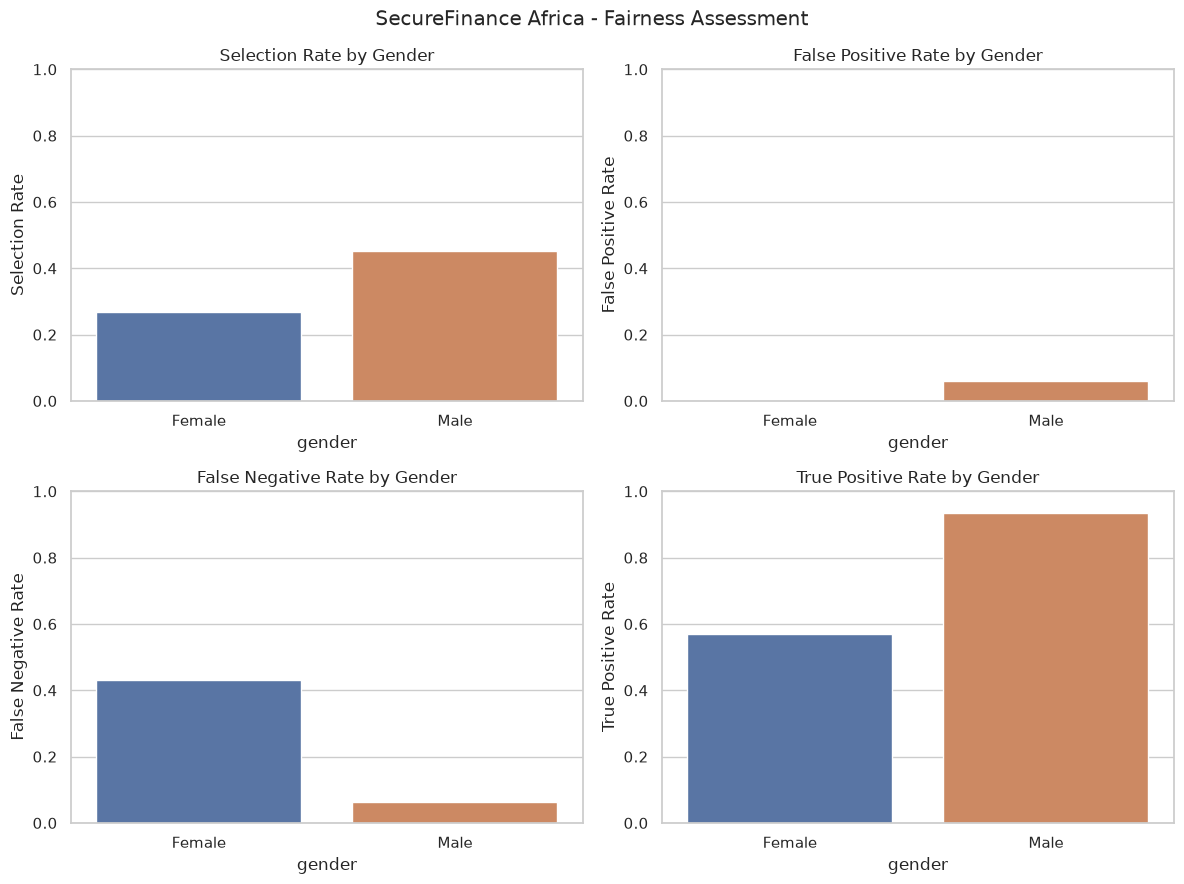

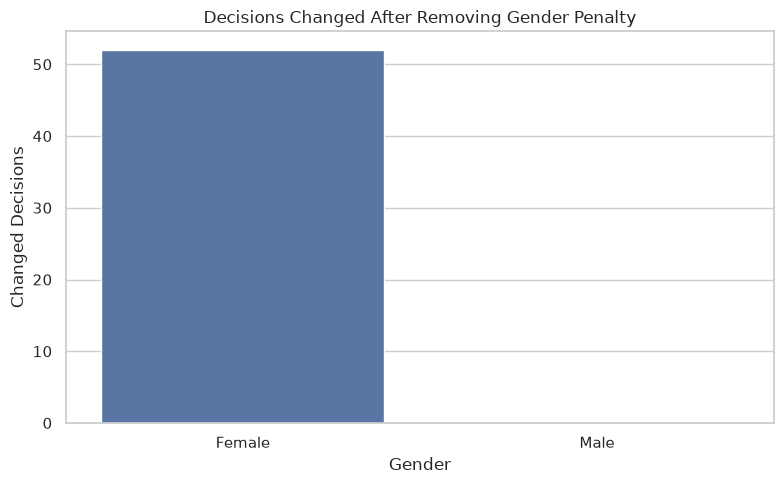

FINAL EVIDENCE REFRESH COMPLETED
All final CSV files exported.
Both visualisations regenerated.
Decision consistency verified.


In [13]:

# STEP 10: FINAL EVIDENCE REFRESH

import os

os.makedirs("analysis_results", exist_ok=True)
os.makedirs("visualisations", exist_ok=True)

# Export final fairness metrics
fairness_metrics.by_group.to_csv(
    "analysis_results/fairness_metrics_by_gender.csv"
)

fairness_metrics.difference(
    method="between_groups"
).to_csv(
    "analysis_results/fairness_group_differences.csv"
)

fairness_metrics.ratio(
    method="between_groups"
).to_csv(
    "analysis_results/fairness_group_ratios.csv"
)

# Export individual decision review
df[[
    "customer_id",
    "gender",
    "financial_score",
    "gender_penalty",
    "prediction_score",
    "actual_eligible",
    "ai_predicted_eligible"
]].to_csv(
    "analysis_results/individual_decision_review.csv",
    index=False
)

# Export counterfactual results
df[[
    "customer_id",
    "gender",
    "financial_score",
    "original_decision",
    "counterfactual_decision",
    "decision_changed"
]].to_csv(
    "analysis_results/counterfactual_results.csv",
    index=False
)

# Regenerate fairness visualisations
metrics_df = fairness_metrics.by_group.reset_index()

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, metric in zip(
    axes.flatten(),
    [
        "Selection Rate",
        "False Positive Rate",
        "False Negative Rate",
        "True Positive Rate"
    ]
):
    sns.barplot(
        data=metrics_df,
        x="gender",
        y=metric,
        hue="gender",
        legend=False,
        ax=ax
    )
    ax.set_title(metric + " by Gender")
    ax.set_ylim(0, 1)

plt.suptitle("SecureFinance Africa - Fairness Assessment")
plt.tight_layout()

plt.savefig(
    "visualisations/fairness_metrics.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Regenerate counterfactual chart
counterfactual_summary = (
    df.groupby("gender")["decision_changed"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=counterfactual_summary,
    x="gender",
    y="decision_changed",
    hue="gender",
    legend=False
)

plt.title("Decisions Changed After Removing Gender Penalty")
plt.xlabel("Gender")
plt.ylabel("Changed Decisions")

plt.tight_layout()

plt.savefig(
    "visualisations/counterfactual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Final consistency checks
assert len(df) == 500
assert df["actual_eligible"].isin([0, 1]).all()
assert df["ai_predicted_eligible"].isin([0, 1]).all()
assert (
    df["original_decision"] == df["ai_predicted_eligible"]
).all()

print("FINAL EVIDENCE REFRESH COMPLETED")
print("All final CSV files exported.")
print("Both visualisations regenerated.")
print("Decision consistency verified.")
